First 5 rows:
Price       Date         Close          High           Low          Open  \
0     2021-10-06  17646.000000  17884.599609  17613.150391  17861.500000   
1     2021-10-07  17790.349609  17857.550781  17763.800781  17810.550781   
2     2021-10-08  17895.199219  17941.849609  17840.349609  17886.849609   
3     2021-10-11  17945.949219  18041.949219  17839.099609  17867.550781   
4     2021-10-12  17991.949219  18008.650391  17864.949219  17915.800781   

Price  Volume  
0      395800  
1      419900  
2      324100  
3      375800  
4      355600  

Dataset shape:
(1235, 6)

Missing values:
Price
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Training data: (986, 5)
Testing data: (247, 5)

Decision Tree Regression
-------------------------
MAE  : 332.14386011266924
MSE  : 185363.38388893273
RMSE : 430.53848131024563
R2   : 0.8346235203386296

Random Forest Regression
-------------------------
MAE  : 244.60157546811735
MSE  : 100487.327

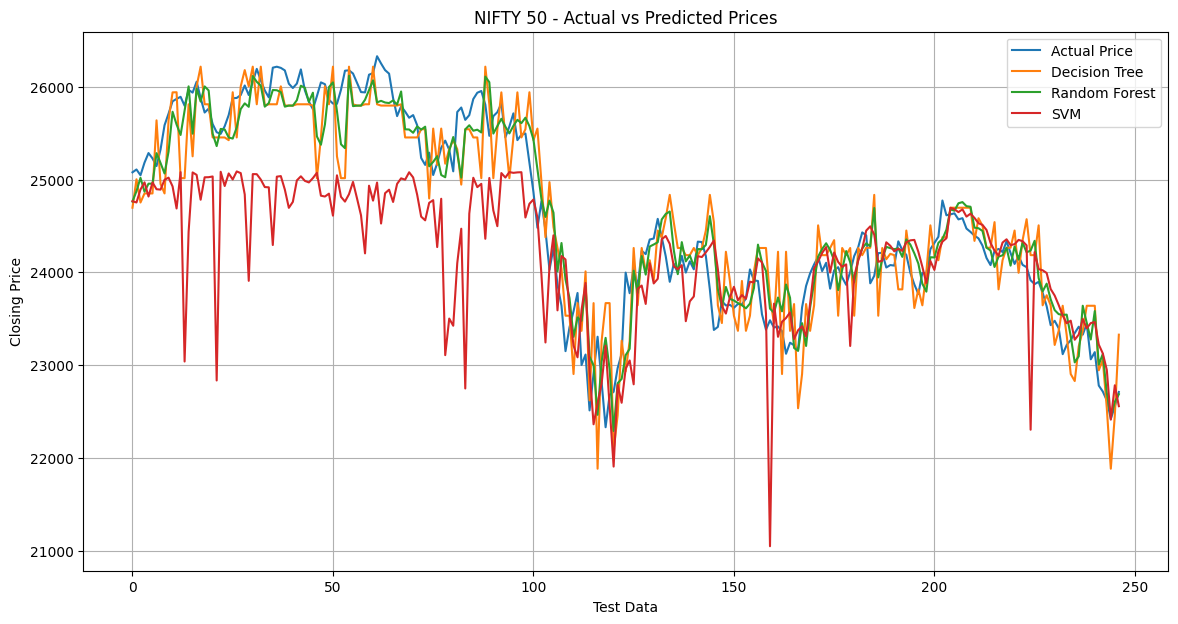

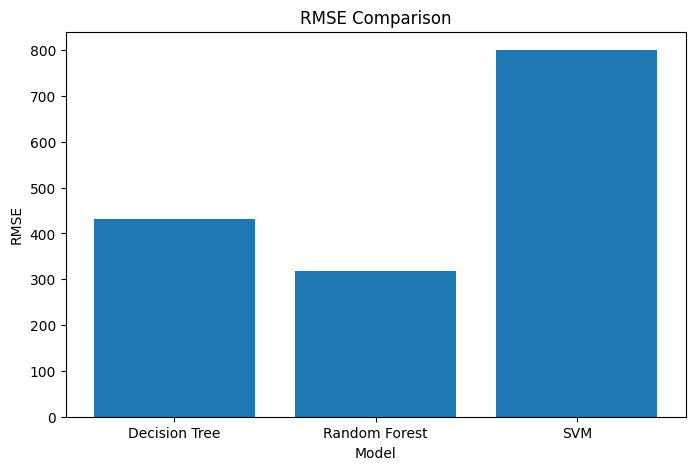

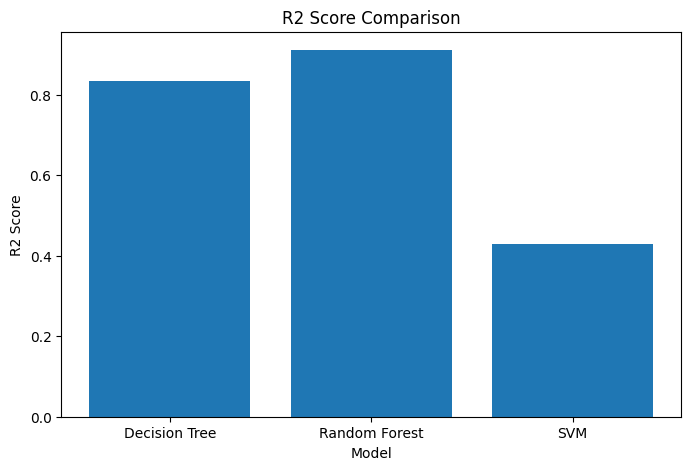


NEXT TRADING DAY PREDICTION
Decision Tree : 23328.55078125
Random Forest : 22686.970390625
SVM           : 22558.169279748614


In [2]:
# ==========================================
# STOCK PRICE PREDICTION
# Decision Tree vs Random Forest vs SVM
# ==========================================

# 1. Install library
!pip -q install yfinance

# 2. Import libraries
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


# ==========================================
# 3. Download NIFTY 50 data
# ==========================================

df = yf.download(
    "^NSEI",
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Handle multi-level columns
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.reset_index()

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)


# ==========================================
# 4. Data preprocessing
# ==========================================

df = df.dropna()

print("\nMissing values:")
print(df.isnull().sum())


# ==========================================
# 5. Create features
# ==========================================

df["Previous_Close"] = df["Close"].shift(1)
df["Previous_Open"] = df["Open"].shift(1)
df["Previous_High"] = df["High"].shift(1)
df["Previous_Low"] = df["Low"].shift(1)
df["Previous_Volume"] = df["Volume"].shift(1)

# Target = next day's closing price
df["Target"] = df["Close"].shift(-1)

df = df.dropna()


# ==========================================
# 6. Select X and y
# ==========================================

features = [
    "Previous_Close",
    "Previous_Open",
    "Previous_High",
    "Previous_Low",
    "Previous_Volume"
]

X = df[features]
y = df["Target"]


# ==========================================
# 7. Train-test split
# ==========================================

split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


# ==========================================
# 8. Decision Tree Regression
# ==========================================

dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)


# ==========================================
# 9. Random Forest Regression
# ==========================================

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)


# ==========================================
# 10. SVM Regression
# ==========================================

svm_model = make_pipeline(
    StandardScaler(),
    SVR(
        kernel="rbf",
        C=100,
        gamma="scale",
        epsilon=0.1
    )
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)


# ==========================================
# 11. Evaluation function
# ==========================================

def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    r2 = r2_score(actual, predicted)

    print("\n" + name)
    print("-------------------------")
    print("MAE  :", mae)
    print("MSE  :", mse)
    print("RMSE :", rmse)
    print("R2   :", r2)

    return mae, mse, rmse, r2


# ==========================================
# 12. Evaluate all models
# ==========================================

dt_results = evaluate_model(
    "Decision Tree Regression",
    y_test,
    dt_pred
)

rf_results = evaluate_model(
    "Random Forest Regression",
    y_test,
    rf_pred
)

svm_results = evaluate_model(
    "SVM Regression",
    y_test,
    svm_pred
)


# ==========================================
# 13. Comparison table
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],

    "MAE": [
        dt_results[0],
        rf_results[0],
        svm_results[0]
    ],

    "MSE": [
        dt_results[1],
        rf_results[1],
        svm_results[1]
    ],

    "RMSE": [
        dt_results[2],
        rf_results[2],
        svm_results[2]
    ],

    "R2 Score": [
        dt_results[3],
        rf_results[3],
        svm_results[3]
    ]
})

print("\n===================================")
print("MODEL COMPARISON")
print("===================================")

print(comparison)


# ==========================================
# 14. Plot actual vs predicted
# ==========================================

plt.figure(figsize=(14, 7))

plt.plot(
    y_test.values,
    label="Actual Price"
)

plt.plot(
    dt_pred,
    label="Decision Tree"
)

plt.plot(
    rf_pred,
    label="Random Forest"
)

plt.plot(
    svm_pred,
    label="SVM"
)

plt.title("NIFTY 50 - Actual vs Predicted Prices")

plt.xlabel("Test Data")

plt.ylabel("Closing Price")

plt.legend()

plt.grid(True)

plt.show()


# ==========================================
# 15. RMSE comparison graph
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["RMSE"]
)

plt.title("RMSE Comparison")

plt.xlabel("Model")

plt.ylabel("RMSE")

plt.show()


# ==========================================
# 16. R2 comparison graph
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["R2 Score"]
)

plt.title("R2 Score Comparison")

plt.xlabel("Model")

plt.ylabel("R2 Score")

plt.show()


# ==========================================
# 17. Predict next trading day's price
# ==========================================

latest_data = X.iloc[[-1]]

dt_next = dt_model.predict(latest_data)
rf_next = rf_model.predict(latest_data)
svm_next = svm_model.predict(latest_data)

print("\n===================================")
print("NEXT TRADING DAY PREDICTION")
print("===================================")

print("Decision Tree :", dt_next[0])
print("Random Forest :", rf_next[0])
print("SVM           :", svm_next[0])